In [1]:

import pandas as pd
from pyodide.http import open_url

# Load the original Auto MPG dataset from my GitHub repository
url = "https://raw.githubusercontent.com/elianmartineztme/IS362_Week8_AutoMPG/main/auto-mpg.data"

# Column names from the UCI Auto MPG documentation
columns = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin", "car_name"
]

# Read the original data, preserving missing values as NaN
df = pd.read_csv(
    open_url(url),
    sep=r"\s+",
    names=columns,
    na_values="?"
)

# Display the first five rows
df.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [2]:

# Review the Auto MPG dataset
print("Dataset dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe())


Dataset dimensions:
(398, 9)

Column names:
['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']

Data types and information:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 26.5 KB

Missing values:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


In [3]:

# Clean the horsepower column
# Missing values marked as '?' were converted to NaN during import

df["horsepower"] = pd.to_numeric(
    df["horsepower"],
    errors="coerce"
)

# Verify the cleanup
print("Horsepower data type:", df["horsepower"].dtype)
print("Missing horsepower values:", df["horsepower"].isna().sum())

# Display rows with missing horsepower
display(df[df["horsepower"].isna()])


Horsepower data type: float64
Missing horsepower values: 6


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
32,25.0,4,98.0,NaN,2046.0,19.0,71,1,ford pinto
126,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick
330,40.9,4,85.0,NaN,1835.0,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,NaN,2905.0,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,NaN,2320.0,15.8,81,2,renault 18i
374,23.0,4,151.0,NaN,3035.0,20.5,82,1,amc concord dl


In [4]:

# Convert origin codes using the original UCI documentation
origin_mapping = {
    1: "USA",
    2: "Europe",
    3: "Japan"
}

df["origin"] = df["origin"].map(origin_mapping)

# Verify the updated values
print("Vehicles by origin:")
print(df["origin"].value_counts())

display(df[["car_name", "origin"]].head(10))


Vehicles by origin:
origin
USA       249
Japan      79
Europe     70
Name: count, dtype: int64


,car_name,origin
0,chevrolet chevelle malibu,USA
1,buick skylark 320,USA
2,plymouth satellite,USA
3,amc rebel sst,USA
4,ford torino,USA
5,ford galaxie 500,USA
6,chevrolet impala,USA
7,plymouth fury iii,USA
8,pontiac catalina,USA
9,amc ambassador dpl,USA


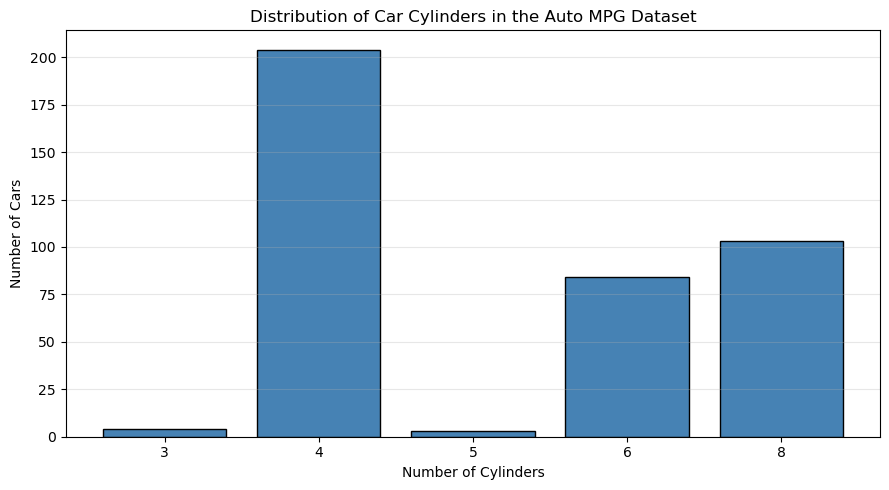

Number of cars by cylinders:
cylinders
3      4
4    204
5      3
6     84
8    103
Name: count, dtype: int64


In [5]:

import matplotlib.pyplot as plt

# Count the number of cars for each cylinder category
cylinder_counts = df["cylinders"].value_counts().sort_index()

# Create the bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    cylinder_counts.index.astype(str),
    cylinder_counts.values,
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of Car Cylinders in the Auto MPG Dataset")
plt.xlabel("Number of Cylinders")
plt.ylabel("Number of Cars")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Display the counts
print("Number of cars by cylinders:")
print(cylinder_counts)


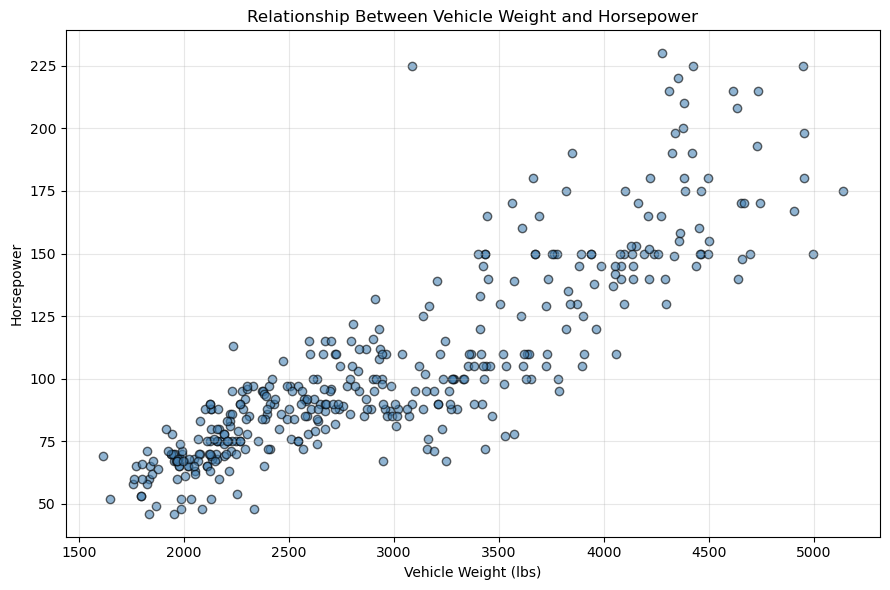

Correlation between weight and horsepower: 0.865


In [6]:

# Create a scatterplot of horsepower vs. weight

plt.figure(figsize=(9, 6))

plt.scatter(
    df["weight"],
    df["horsepower"],
    color="steelblue",
    alpha=0.6,
    edgecolors="black"
)

plt.title("Relationship Between Vehicle Weight and Horsepower")
plt.xlabel("Vehicle Weight (lbs)")
plt.ylabel("Horsepower")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate the correlation
correlation = df["weight"].corr(df["horsepower"])

print("Correlation between weight and horsepower:",
      round(correlation, 3))


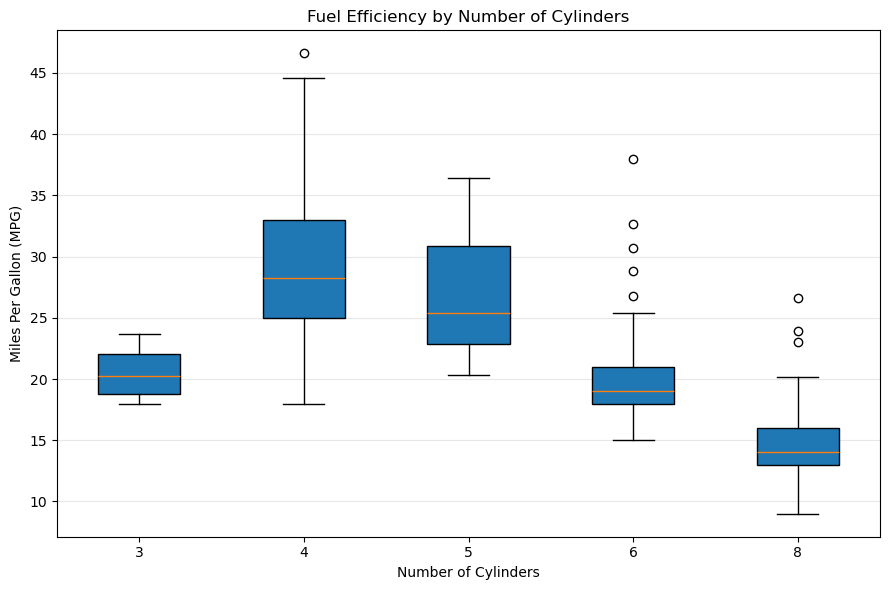

Average MPG by number of cylinders:
cylinders
3    20.55
4    29.29
5    27.37
6    19.99
8    14.96
Name: mpg, dtype: float64


In [7]:

import matplotlib.pyplot as plt

# Research question:
# Do cars with more cylinders generally have lower MPG?

# Prepare MPG values for each cylinder category
cylinder_groups = sorted(df["cylinders"].unique())

mpg_groups = [
    df.loc[df["cylinders"] == c, "mpg"].dropna()
    for c in cylinder_groups
]

# Create the boxplot
plt.figure(figsize=(9, 6))

plt.boxplot(
    mpg_groups,
    tick_labels=cylinder_groups,
    patch_artist=True
)

plt.title("Fuel Efficiency by Number of Cylinders")
plt.xlabel("Number of Cylinders")
plt.ylabel("Miles Per Gallon (MPG)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate average MPG by cylinder count
print("Average MPG by number of cylinders:")
print(df.groupby("cylinders")["mpg"].mean().round(2))


## Analysis and Conclusion

**Research Question: Do cars with more cylinders generally have lower fuel efficiency?**

For my analysis, I wanted to explore whether the number of cylinders in a vehicle is related to its fuel efficiency. I chose this question because I am interested in cars, and I wanted to see how differences in engine configurations might affect gas mileage.

The boxplot shows that vehicles with four cylinders generally have higher MPG values than vehicles with six or eight cylinders. Eight-cylinder vehicles have some of the lowest fuel efficiency in the dataset. This suggests that cars with more cylinders tend to consume more fuel, although there are exceptions.

Another interesting finding was the strong positive correlation of 0.865 between vehicle weight and horsepower. This indicates that heavier vehicles generally have more horsepower. Together, these results suggest that engine configuration, vehicle weight, and performance are important factors to consider when comparing fuel efficiency.

Overall, this assignment helped me understand how data cleaning and visualization can reveal patterns that are not immediately obvious when looking at raw data. It also showed me how pandas and Matplotlib can be used to explore relationships between variables and support conclusions with actual data.